# Machine learning challenges - Universidad EIA

**Objective:** solve three challenges of the machine learning course:
1. **Decision tree** to predict if a person continues studying (`Datos_Conitnue_Edu.xlsx`, 2.000 people)
2. **Gaussian Naive Bayes** with the same data, to compare
3. **K-means** to make groups of 37 candy bars by their nutrition (`CandyBars.xlsx`)

The datasets were given by the course.

## Part 1. Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score  # to split the data in train and test
from sklearn.tree import DecisionTreeClassifier, plot_tree              # decision tree model
from sklearn.naive_bayes import GaussianNB                              # Naive Bayes model
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
from sklearn.preprocessing import StandardScaler                        # to scale the data before K-means
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

## Part 2. Continue education data

In [2]:
sv = pd.read_excel("data/Datos_Conitnue_Edu.xlsx")
print("Shape:", sv.shape)
print("Duplicates:", sv.duplicated().sum(), "| missing values:", sv.isnull().sum().sum())
sv2 = sv.drop_duplicates()     # new dataset without duplicates
print("Share of people that continue studying:", round(sv2["ContinueEdu"].mean(), 3))
sv2.describe().T

Shape: (2000, 8)
Duplicates: 14 | missing values: 0
Share of people that continue studying: 0.104


,count,mean,std,min,25%,50%,75%,max
Age,1986.0,54.633938,13.667053,28.0,43.0,55.0,66.0,80.0
Marriage,1986.0,25.522155,14.258738,-4.0,14.0,25.0,38.0,53.0
Income,1986.0,90308.157100,55750.241024,10000.0,47000.0,78000.0,119000.0,262000.0
Edu,1986.0,1.861531,0.838290,1.0,1.0,2.0,3.0,3.0
Own,1986.0,0.592145,0.491560,0.0,0.0,1.0,1.0,1.0
Pet,1986.0,0.936556,0.243821,0.0,1.0,1.0,1.0,1.0
City,1986.0,0.294562,0.455960,0.0,0.0,0.0,1.0,1.0
ContinueEdu,1986.0,0.103726,0.304982,0.0,0.0,0.0,0.0,1.0


Only around 10% of the people continue studying, so the classes are imbalanced. Accuracy alone is not a good metric here, we also need to look at precision and recall of class 1.

In [3]:
y = sv2["ContinueEdu"]
x = sv2.drop(["ContinueEdu"], axis=1)
# 75% train and 25% test, stratified so both sets have the same share of class 1
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.75, random_state=42, stratify=y)
print("Train:", x_train.shape, "| Test:", x_test.shape)

Train: (1489, 7) | Test: (497, 7)


## Part 3. Decision tree

Instead of choosing the depth by hand, we choose it with 5-fold cross-validation, so the tree does not grow too much (overfitting).

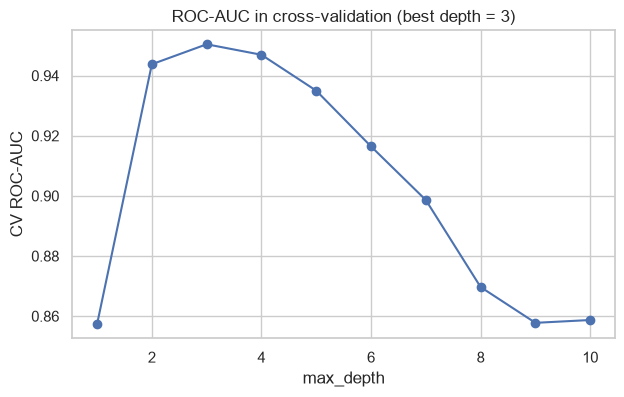

In [4]:
profundidades = range(1, 11)
auc_cv = []
for d in profundidades:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    auc_cv.append(cross_val_score(dt, x_train, y_train, cv=5, scoring="roc_auc").mean())
mejor = profundidades[int(np.argmax(auc_cv))]

plt.figure(figsize=(7, 4))
plt.plot(profundidades, auc_cv, marker="o")
plt.title(f"ROC-AUC in cross-validation (best depth = {mejor})")
plt.xlabel("max_depth")
plt.ylabel("CV ROC-AUC")
plt.show()

In [5]:
dt = DecisionTreeClassifier(max_depth=mejor, random_state=42)
dt.fit(x_train, y_train)          # we train the model
y_pred = dt.predict(x_test)
print(classification_report(y_test, y_pred))
print("Test ROC-AUC:", round(roc_auc_score(y_test, dt.predict_proba(x_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       445
           1       0.93      0.75      0.83        52

    accuracy                           0.97       497
   macro avg       0.95      0.87      0.91       497
weighted avg       0.97      0.97      0.97       497

Test ROC-AUC: 0.93


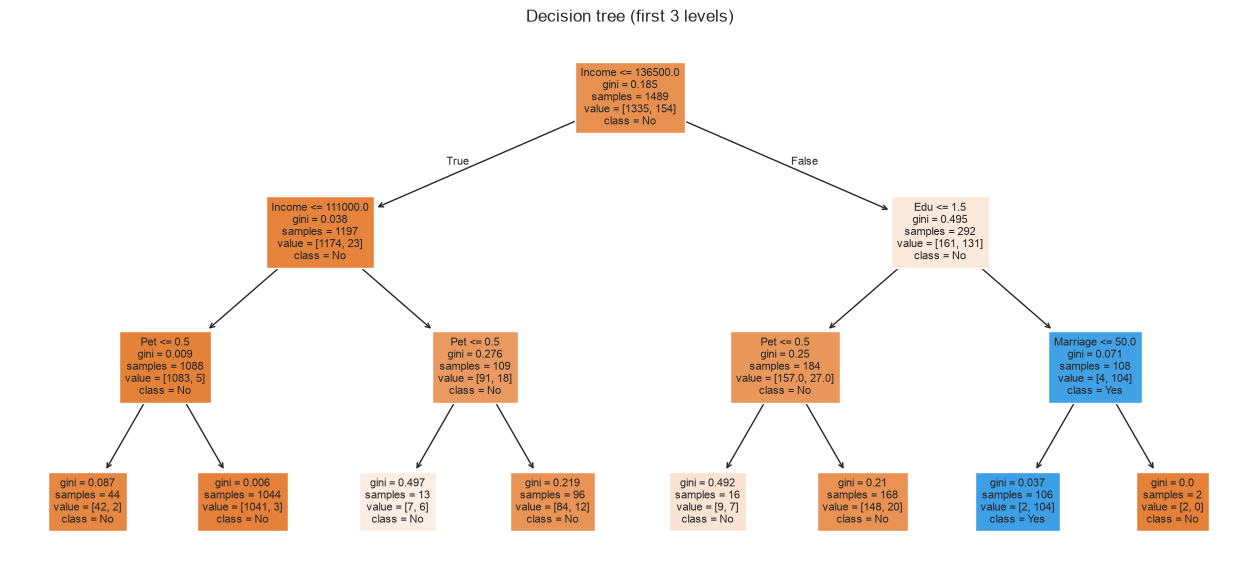

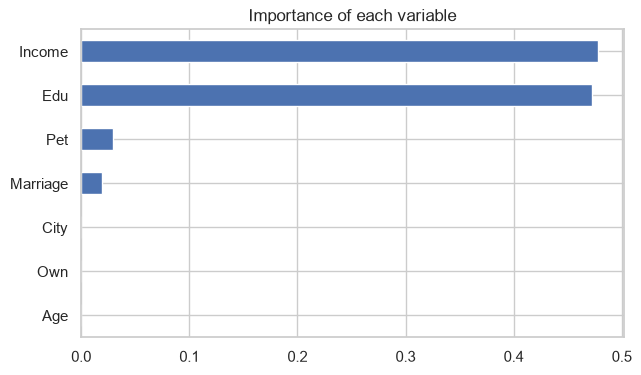

In [6]:
plt.figure(figsize=(16, 7))
plot_tree(dt, feature_names=x.columns, class_names=["No", "Yes"], filled=True, max_depth=3, fontsize=8)
plt.title("Decision tree (first 3 levels)")
plt.show()

pd.Series(dt.feature_importances_, index=x.columns).sort_values().plot.barh(figsize=(7, 4))
plt.title("Importance of each variable")
plt.show()

## Part 4. Naive Bayes

In [7]:
nb = GaussianNB()
nb.fit(x_train, y_train)
print(classification_report(y_test, nb.predict(x_test)))
print("Test ROC-AUC:", round(roc_auc_score(y_test, nb.predict_proba(x_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0       0.96      0.93      0.95       445
           1       0.55      0.67      0.60        52

    accuracy                           0.91       497
   macro avg       0.75      0.80      0.78       497
weighted avg       0.92      0.91      0.91       497

Test ROC-AUC: 0.935


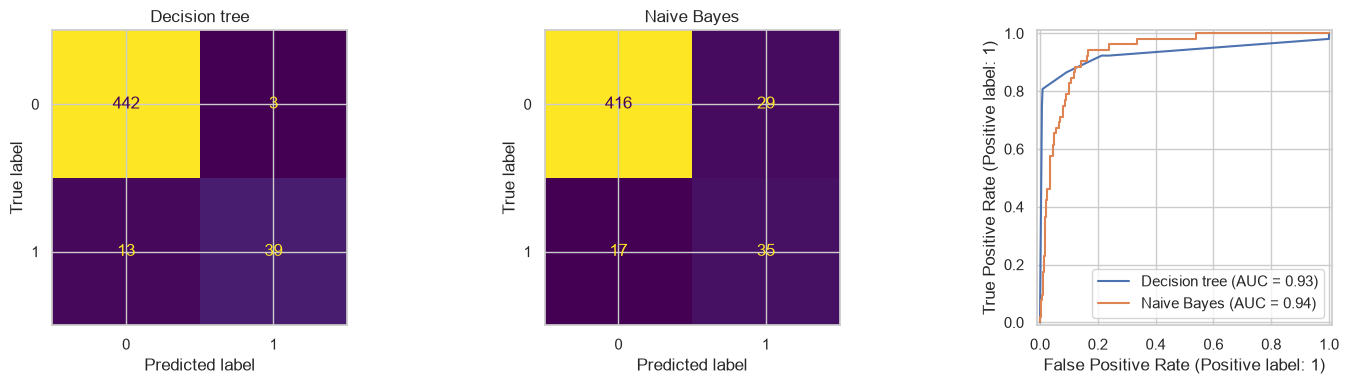

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_estimator(dt, x_test, y_test, ax=axes[0], colorbar=False)
axes[0].set_title("Decision tree")
ConfusionMatrixDisplay.from_estimator(nb, x_test, y_test, ax=axes[1], colorbar=False)
axes[1].set_title("Naive Bayes")
RocCurveDisplay.from_estimator(dt, x_test, y_test, ax=axes[2], name="Decision tree")
RocCurveDisplay.from_estimator(nb, x_test, y_test, ax=axes[2], name="Naive Bayes")
plt.tight_layout()
plt.show()

Both models have a similar ROC-AUC, but the tree has much better precision in class 1: Naive Bayes says that more people will continue studying, and many of them are wrong. The choice depends on what error is more expensive.

## Part 5. K-means with the candy bars

We remove the name (`Brands`) and the variable `prospect`, and we scale the data so calories (big numbers) do not dominate the distances. Then we choose k with the elbow method and the silhouette.

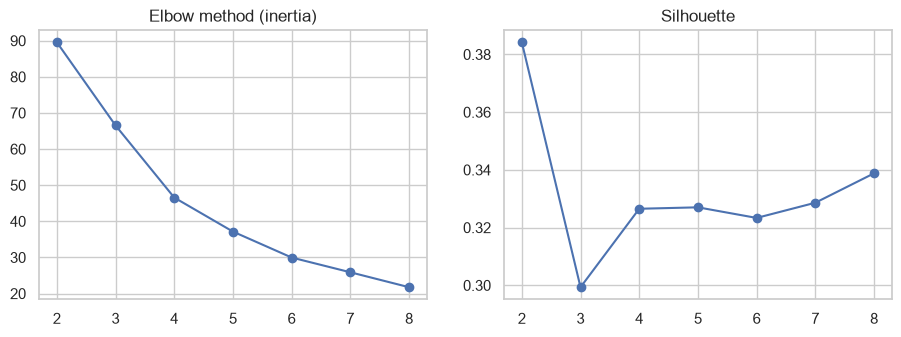

Chosen k: 2


In [9]:
candy = pd.read_excel("data/CandyBars.xlsx").dropna()
variables = ["Calories", "Fat", "Protein", "Carb"]
scaler = StandardScaler()
xs = scaler.fit_transform(candy[variables])

inercia, silueta = [], []
k_n = range(2, 9)
for k in k_n:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(xs)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(xs, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_n, inercia, marker="o")
axes[0].set_title("Elbow method (inertia)")
axes[1].plot(k_n, silueta, marker="o")
axes[1].set_title("Silhouette")
plt.show()
k = list(k_n)[int(np.argmax(silueta))]
print("Chosen k:", k)

In [10]:
km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(xs)
candy["cluster"] = km.labels_
perfil = candy.groupby("cluster")[variables + ["prospect"]].mean().round(1)
perfil["count"] = candy["cluster"].value_counts().sort_index()
print("Silhouette:", round(silhouette_score(xs, km.labels_), 3))
perfil

Silhouette: 0.384


,Calories,Fat,Protein,Carb,prospect,count
cluster,,,,,,
0,235.9,12.6,3.8,29.4,1.3,27
1,198.8,4.9,1.4,40.4,2.6,10


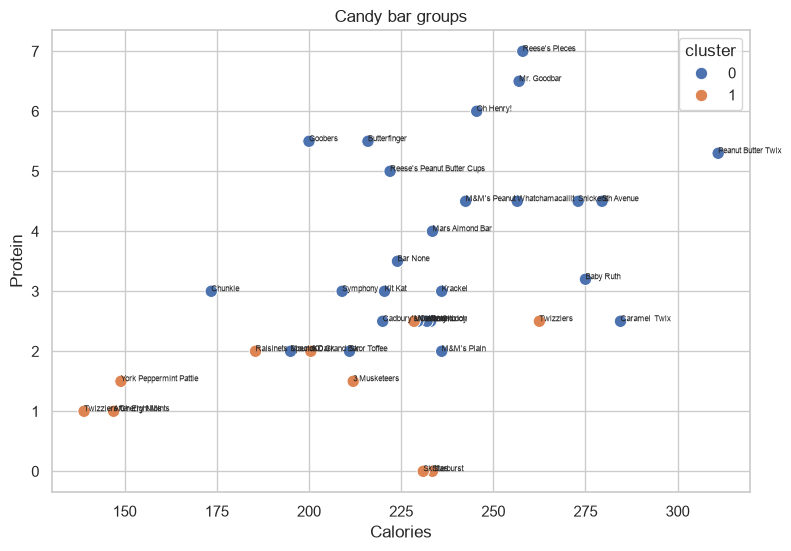

,Brands,cluster,Calories,Fat,Protein,Carb
0,Peanut Butter Twix,0,311.0,18.5,5.3,31.4
1,Baby Ruth,0,275.0,13.0,3.2,39.0
2,Caramel Twix,0,284.5,14.0,2.5,37.5
3,5th Avenue,0,279.5,12.5,4.5,41.0
4,Snickers,0,273.0,14.0,4.5,34.0
6,Reese's Pieces,0,258.0,11.5,7.0,34.0
7,Mr. Goodbar,0,257.0,16.0,6.5,25.5
8,Whatchamacallit,0,256.5,13.0,4.5,30.0
12,M&M's Plain,0,236.0,10.0,2.0,34.0
9,Oh Henry!,0,245.5,9.5,6.0,37.0


In [11]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=candy, x="Calories", y="Protein", hue="cluster", palette="deep", s=80)
for i, fila in candy.iterrows():
    plt.annotate(fila["Brands"], (fila["Calories"], fila["Protein"]), fontsize=6)
plt.title("Candy bar groups")
plt.show()
candy.sort_values("cluster")[["Brands", "cluster"] + variables]

## Conclusions

- The decision tree predicts very well who does not continue studying and finds 75% of the people who continue, with a precision of 93%.
- Naive Bayes has a similar ROC-AUC but much lower precision for the minority class.
- The silhouette chooses 2 groups of candy bars: chocolate bars with more fat and protein, and candies with less fat and more sugar (carbs).